# **Notebook 3: Feature Selection**

This notebook performs model-specific feature selection using three machine learning approaches: Logistic Regression with L1 regularization (LASSO), Random Forest, and Artificial Neural Network (ANN).

The notebook uses the stratified 80/20 train-test partitions created in NB1. The training portion is used for feature selection, while the held-out test portion is retained and is not used in the feature-selection procedures.

Three complementary feature-selection procedures are applied:

1. **LASSO stability selection** for Logistic Regression, based on the frequency with which predictors retain non-zero coefficients across bootstrap samples.
2. **Permutation importance with Random Forest**, based on the change in ROC-AUC when individual predictors are randomly permuted.
3. **Permutation importance with Artificial Neural Network**, using the same general permutation-based framework to identify predictors contributing to nonlinear classification performance.

The selected features are saved separately for each model and are subsequently used in NB4 for model development and hyperparameter tuning.

### **Import Libraries**

In [1]:
import re
import os
import json
import time
import warnings
import shutil

from pathlib import Path
from tqdm import tqdm

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
from sklearn.utils import resample
from sklearn.exceptions import ConvergenceWarning

### **Configuration**

In [2]:
# Reproducibility and cross-validation
RANDOM_STATE = 42
N_FOLDS = 5

# Feature selection
PI_THR = 0.60
C_VALUES = [0.05, 0.06, 0.07, 0.1, 0.3, 0.5, 0.6, 0.7]

# Bootstrap settings
N_BOOTSTRAPS_LR = 100
N_BOOTSTRAPS_RF = 30
N_BOOTSTRAPS_ANN = 30

# Permutation importance
N_REPEATS_RF = 10
N_REPEATS_ANN = 10

# Model optimization
LASSO_MAX_ITER = 10000
ANN_MAX_ITER = 2000

### **Directories**

In [3]:
SOURCE_DIR = Path.cwd().parent.parent / "Outputs"
OUT_DIR = SOURCE_DIR.parent / "NB_OUTS1_TRAINONLY"
FOLDS_DIR = OUT_DIR / "folds"

if not (SOURCE_DIR / "NB1_train_LR.csv").exists():
    raise FileNotFoundError("NB1_train_LR.csv not found.")

OUT_DIR.mkdir(parents=True, exist_ok=True)
FOLDS_DIR.mkdir(parents=True, exist_ok=True)

print("Source directory:", SOURCE_DIR)
print("Output directory:", OUT_DIR)

Source directory: /home/abigailching/Thesis/Outputs
Output directory: /home/abigailching/Thesis/NB_OUTS1_TRAINONLY


### **Load Outputs from NB1**

In [4]:
lr_train = pd.read_csv(SOURCE_DIR / "NB1_train_LR.csv", index_col="orig_index")
lr_test = pd.read_csv(SOURCE_DIR / "NB1_test_LR.csv", index_col="orig_index")

rf_train = pd.read_csv(SOURCE_DIR / "NB1_train_RF_ANN.csv", index_col="orig_index")
rf_test = pd.read_csv(SOURCE_DIR / "NB1_test_RF_ANN.csv", index_col="orig_index")

**Validate datasets**

In [5]:
# Check respondent indices
assert lr_train.index.is_unique and lr_test.index.is_unique
assert rf_train.index.is_unique and rf_test.index.is_unique

assert lr_train.index.equals(rf_train.index)
assert lr_test.index.equals(rf_test.index)

assert set(lr_train.index).isdisjoint(set(lr_test.index))

# Check target consistency
assert lr_train["depressed_flag"].equals(rf_train["depressed_flag"])
assert lr_test["depressed_flag"].equals(rf_test["depressed_flag"])

# Check target and leakage variables
for name, frame in [
    ("LR train", lr_train), ("LR test", lr_test),
    ("RF/ANN train", rf_train), ("RF/ANN test", rf_test)
]:
    assert "depressed_flag" in frame.columns, f"{name}: target missing"
    assert "cesd" not in frame.columns, f"{name}: CES-D leakage detected"

# Check train-test feature consistency
assert set(lr_train.columns) == set(lr_test.columns)
assert set(rf_train.columns) == set(rf_test.columns)

# Expected sample sizes and class counts
assert len(lr_train) == 530 and len(lr_test) == 133
assert int(lr_train["depressed_flag"].sum()) == 78
assert int(lr_test["depressed_flag"].sum()) == 19

# Extract target variables
y_train = lr_train["depressed_flag"].astype(int)
y_test = lr_test["depressed_flag"].astype(int)

assert set(y_train.unique()).issubset({0, 1})
assert set(y_test.unique()).issubset({0, 1})

### **Prepare Model Features**

In [6]:
X_lr = lr_train.drop(columns=["depressed_flag", "cesd"], errors="ignore").copy()
X_lr_test = lr_test.drop(columns=["depressed_flag", "cesd"], errors="ignore").copy()

X_rfann = rf_train.drop(columns=["depressed_flag", "cesd"], errors="ignore").copy()
X_rfann_test = rf_test.drop(columns=["depressed_flag", "cesd"], errors="ignore").copy()

# Validate predictors
for label, frame in [
    ("LR train", X_lr), ("LR test", X_lr_test),
    ("RF/ANN train", X_rfann), ("RF/ANN test", X_rfann_test)
]:
    assert not frame.isna().any().any(), f"{label} contains missing values"
    assert all(
        pd.api.types.is_numeric_dtype(frame[col])
        for col in frame.columns), f"{label} contains nonnumeric columns"

# Confirm feature alignment
assert X_lr.columns.equals(X_lr_test.columns)
assert X_rfann.columns.equals(X_rfann_test.columns)

print(f"LR candidates: {X_lr.shape[1]}")
print(f"RF/ANN candidates: {X_rfann.shape[1]}")

print(f"Train: {len(y_train)} | HDS={int(y_train.sum())} | MNDS={int((y_train == 0).sum())}")
print(f"Test:  {len(y_test)} | HDS={int(y_test.sum())} | MNDS={int((y_test == 0).sum())}")

print("Dataset validation completed successfully.")

LR candidates: 582
RF/ANN candidates: 154
Train: 530 | HDS=78 | MNDS=452
Test:  133 | HDS=19 | MNDS=114
Dataset validation completed successfully.


### **Load Preprocessing Checkpoint**

In [7]:
# Categorical level mapping
level_map = SOURCE_DIR / "NB1_RF_ANN_level_order.csv"

if level_map.exists():
    shutil.copy2(level_map, OUT_DIR / level_map.name)
    print("Categorical level mapping copied.")

# Load deterministic preprocessing checkpoint
PRELEARN_FILE = SOURCE_DIR / "NB1_prelearn_cleaned_NCR.pkl"

if not PRELEARN_FILE.exists():
    raise FileNotFoundError("Missing NB1_prelearn_cleaned_NCR.pkl. ""Rerun NB1 to generate the preprocessing checkpoint.")

prelearn = pd.read_pickle(PRELEARN_FILE)

prelearn_df = prelearn["data"].copy()
prelearn_labels = prelearn["spss_value_labels"]

# Validate checkpoint alignment
assert set(prelearn_df.index) == set(lr_train.index).union(lr_test.index)
assert set(prelearn["train_idx"]) == set(lr_train.index)
assert set(prelearn["test_idx"]) == set(lr_test.index)

print("Preprocessing checkpoint loaded and validated.")

Categorical level mapping copied.
Preprocessing checkpoint loaded and validated.


### **Shared Selection Functions**

A selector receives only its supplied training rows. Any scaling, bootstrap resampling, permutation holdout, and inner regularization search are restricted to those rows. The outer CV validation rows are not used.

**LASSO Regularization Search**

In [8]:
def choose_lasso_c(X, y, seed):
    """Select C using stratified inner cross-validation."""
    inner_cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)

    rows = []

    for c in C_VALUES:
        pipe = Pipeline([
            ("scaler", StandardScaler()),
            ("lr", LogisticRegression(
                C=c,
                penalty="l1",
                solver="saga",
                class_weight="balanced",
                max_iter=LASSO_MAX_ITER,
                random_state=seed))
        ])

        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)
            scores = cross_val_score(pipe, X, y, cv=inner_cv, scoring="roc_auc", n_jobs=1)

        rows.append({
            "C": float(c), "mean_auc": float(np.mean(scores)), 
            "std_auc": float(np.std(scores))
        })

    cv_table = pd.DataFrame(rows)

    # Select highest mean AUC; ties favor the lower C.
    best = cv_table.sort_values(["mean_auc", "C"], ascending=[False, True]).iloc[0]
    
    return float(best["C"]), cv_table

**LASSO Bootstrap Stability**

In [9]:
def lasso_stability(X, y, selected_c, seed):
    """Evaluate LASSO feature-selection stability through bootstrapping."""
    coefficients = []

    for b in range(N_BOOTSTRAPS_LR):
        Xb, yb = resample(X, y, replace=True, n_samples=len(X), random_state=seed + b)

        scaler = StandardScaler()
        Xb_scaled = scaler.fit_transform(Xb)

        model = LogisticRegression(
            C=selected_c,
            penalty="l1",
            solver="saga",
            class_weight="balanced",
            max_iter=LASSO_MAX_ITER,
            random_state=seed + b
        )

        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)
            model.fit(Xb_scaled, yb)

        coefficients.append(model.coef_[0].copy())

    coef_array = np.asarray(coefficients)

    table = pd.DataFrame({
        "feature": X.columns, "coef_mean": coef_array.mean(axis=0),
        "coef_std": coef_array.std(axis=0), "selection_frequency": (coef_array != 0).mean(axis=0)
    })

    table = table.sort_values(["selection_frequency", "feature"], ascending=[False, True])
    table["selected"] = table["selection_frequency"] >= PI_THR

    features = table.loc[table["selected"], "feature"].tolist()

    if not features:
        raise RuntimeError("No LR features selected. Review C and selection stability.")

    return features, table

**Balanced Bootstrap**

In [10]:
def balanced_bootstrap(X, y, seed):
    """Generate a balanced bootstrap sample from the supplied training data."""
    rng = np.random.RandomState(seed)
    y_array = np.asarray(y)

    idx_0 = np.flatnonzero(y_array == 0)
    idx_1 = np.flatnonzero(y_array == 1)

    if len(idx_0) == 0 or len(idx_1) == 0:
        raise ValueError("Both target classes must be present.")

    indices = np.concatenate([
        rng.choice(idx_0, size=len(idx_0), replace=True),
        rng.choice(idx_1, size=len(idx_0), replace=True)
    ])

    rng.shuffle(indices)

    return X.iloc[indices], y.iloc[indices]

**RF/ANN Permutation Stability**

In [11]:
def permutation_stability(X, y, algorithm, seed):
    """Evaluate RF or ANN feature stability using an internal holdout."""
    if algorithm not in ("RF", "ANN"):
        raise ValueError("algorithm must be 'RF' or 'ANN'.")

    # Internal split uses only the supplied training data.
    X_pool, X_perm, y_pool, y_perm = train_test_split(X, y, test_size=0.20, stratify=y, random_state=seed)

    n_boot = N_BOOTSTRAPS_RF if algorithm == "RF" else N_BOOTSTRAPS_ANN
    n_repeat = N_REPEATS_RF if algorithm == "RF" else N_REPEATS_ANN

    importance_rows = []

    for b in range(n_boot):
        if algorithm == "RF":
            Xb, yb = resample(X_pool, y_pool, replace=True, n_samples=len(X_pool), random_state=seed + b)
            model = RandomForestClassifier(
                n_estimators=200, max_depth=8,
                class_weight="balanced", random_state=seed + b, n_jobs=-1
            )

            model.fit(Xb, yb)

            result = permutation_importance(
                model, X_perm, y_perm,
                n_repeats=n_repeat, scoring="roc_auc",
                random_state=seed + b, n_jobs=1
            )

        else:  # ANN
            Xb, yb = balanced_bootstrap(X_pool, y_pool, seed + b)
            scaler = StandardScaler()
            Xb_scaled = scaler.fit_transform(Xb)

            model = MLPClassifier(
                hidden_layer_sizes=(32, 16), activation="relu",
                solver="adam", alpha=0.01,
                max_iter=ANN_MAX_ITER, random_state=seed + b
            )

            with warnings.catch_warnings():
                warnings.simplefilter("ignore", ConvergenceWarning)
                model.fit(Xb_scaled, yb)

            result = permutation_importance(
                model, scaler.transform(X_perm),y_perm, 
                n_repeats=n_repeat, scoring="roc_auc", 
                random_state=seed + b, n_jobs=1
            )

        importance_rows.append(result.importances_mean)

    importance_array = np.asarray(importance_rows)

    table = pd.DataFrame({
        "feature": X.columns, "importance_mean": importance_array.mean(axis=0),
        "importance_std": importance_array.std(axis=0), "selection_frequency": (importance_array > 0).mean(axis=0)
    })

    table = table.sort_values(["importance_mean", "feature"], ascending=[False, True])
    table["selected"] = ((table["selection_frequency"] >= PI_THR) & (table["importance_mean"] > 0))

    features = table.loc[table["selected"], "feature"].tolist()

    if not features:
        raise RuntimeError(f"No {algorithm} features selected. Review stability settings.")
    return features, table

### **Fold-Specific Preprocessing**

The functions below reproduce the numeric-conversion tests, rare-category threshold, SPSS-ordered coding, one-hot rule, skip-pattern recode, and `-1` sentinel. Only the fitting subset changes: each outer fold's determine conversion/pooling/categories. The validation rows are transformed using those fixed decisions and do not determine them.

**Preprocessing settings**

In [12]:
_FOLD_NUMERIC_CANDIDATES = [
    "B8A_1", "B8A_2", "C3", "C4", "C5",
    "G14", "G28", "E7", "E10B", "E10E"
]

_FOLD_RARE_THRESHOLD = 0.01
_FOLD_SENTINEL = -1.0

**Numeric conversion helpers**

In [13]:
def _fold_extract_number(val):
    """Extract a numeric value from a response."""
    if pd.isna(val):
        return np.nan
    if isinstance(val, (int, float)):
        return float(val)
        
    match = re.search(r"\d+(\.\d+)?", str(val))
    return float(match.group()) if match else np.nan

def _fold_safe_numeric_convert_decision(series):
    """Allow conversion only with complete numeric coverage and unique mappings."""
    s = series.astype(object)
    non_missing = s.dropna()

    if non_missing.empty:
        return False

    parsed = non_missing.apply(_fold_extract_number)
    complete_coverage = parsed.notna().all()

    n_labels = non_missing.astype(str).nunique()
    n_numbers = parsed.nunique()

    return complete_coverage and n_numbers == n_labels

**Categorical level ordering**

In [14]:
def _fold_ordered_levels(col, levels):
    """Order categorical levels using the original SPSS value labels."""
    label_to_code = {}

    for code, label in prelearn_labels.get(col, {}).items():
        try:
            label_to_code[str(label)] = float(code)
        except (TypeError, ValueError):
            pass

    def sort_key(level):
        if level in label_to_code:
            return (0, label_to_code[level], level)
        try:
            return (0, float(level), level)
        except ValueError:
            return (2, 0.0, level) if level == "Others" else (1, 0.0, level)

    return sorted(levels, key=sort_key)

**Fold-specific preprocessing**

In [15]:
def _fold_refit_preprocessing(train_indices, val_indices):
    """
    Refit preprocessing using outer-fold training rows only.

    Returns:
        lr: LR representation for training and validation rows.
        rf: RF/ANN representation for training and validation rows.
    """
    # Validate fold indices
    train_indices = list(train_indices)
    val_indices = list(val_indices)

    assert len(train_indices) == len(set(train_indices))
    assert len(val_indices) == len(set(val_indices))
    assert set(train_indices).isdisjoint(set(val_indices))

    idx = train_indices + val_indices

    assert set(idx).issubset(prelearn_df.index)

    df = prelearn_df.loc[idx].copy()

    # Mixed-format detection
    mixed_format_cols = []

    candidate_cols = df.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()

    for col in candidate_cols:
        train_values = (df.loc[train_indices, col].dropna().astype(str).str.strip())

        has_pure_numeric = train_values.str.match(r"^\d+(\.\d+)?$").any()
        has_number_with_label = train_values.str.match(r"^\d+(\.\d+)?\s+\S").any()
        has_pure_text = train_values.str.match(r"^[A-Za-z]").any()

        if has_number_with_label or (has_pure_numeric and has_pure_text):
            mixed_format_cols.append(col)

    # Numeric conversion
    candidates = [col for col in dict.fromkeys(_FOLD_NUMERIC_CANDIDATES + mixed_format_cols) if col in df.columns]
    for col in candidates:
        if pd.api.types.is_numeric_dtype(df[col]):
            continue

        if _fold_safe_numeric_convert_decision(df.loc[train_indices, col]):
            df[col] = (df[col].apply(_fold_extract_number).astype(float))

    # Rare-category pooling
    predictor_cols = [col for col in df.columns if col not in ("cesd", "depressed_flag")]
    high_card_cols = [col for col in predictor_cols
        if (not pd.api.types.is_numeric_dtype(df[col]) and df.loc[train_indices, col].nunique(dropna=True) > 8)
    ]

    for col in high_card_cols:
        train_frequency = (df.loc[train_indices, col].value_counts(normalize=True, dropna=True))
        rare_levels = train_frequency[train_frequency < _FOLD_RARE_THRESHOLD].index.tolist()
        
        df[col] = df[col].apply(lambda x: "Others" if x in rare_levels else x)

    # Skip-pattern recoding
    df.loc[df["ever_sex"] == "No", "age_first_sex"] = 0

    # RF/ANN categorical encoding
    rf = df.drop(columns=["cesd"], errors="ignore").copy()

    cat_cols_rf = [col for col in rf.columns
        if (col != "depressed_flag" and not pd.api.types.is_numeric_dtype(rf[col]))
    ]

    for col in cat_cols_rf:
        series = rf[col].astype(object)
        levels = _fold_ordered_levels(col, series.loc[train_indices].dropna().astype(str).unique().tolist())

        mapping = {level: float(i) for i, level in enumerate(levels)}

        rf[col] = series.apply(lambda x: mapping.get(str(x), _FOLD_SENTINEL) if pd.notna(x) else _FOLD_SENTINEL)

    # Fill remaining numeric missing values
    num_cols_rf = [col for col in rf.columns
        if (col != "depressed_flag" and pd.api.types.is_numeric_dtype(rf[col]))
    ]

    rf[num_cols_rf] = rf[num_cols_rf].fillna(_FOLD_SENTINEL)

    # LR one-hot encoding
    cat_cols_lr = [
        col for col in df.select_dtypes(include=["object", "category"]).columns
        if col != "cesd"
    ]

    # Fit dummy-column vocabulary using training rows only
    lr_train_encoded = pd.get_dummies(df.loc[train_indices], columns=cat_cols_lr, dummy_na=False, dtype=int)

    # Transform validation rows using the training vocabulary
    lr_val_encoded = pd.get_dummies(df.loc[val_indices], columns=cat_cols_lr, dummy_na=False, dtype=int
    ).reindex(columns=lr_train_encoded.columns,fill_value=0)

    lr = pd.concat([lr_train_encoded, lr_val_encoded]).loc[idx]

    # Fill remaining numeric missing values
    lr = lr.drop(columns=["cesd"], errors="ignore")
    lr_predictors = [col for col in lr.columns if col != "depressed_flag"]
    lr[lr_predictors] = lr[lr_predictors].fillna(_FOLD_SENTINEL)

    # LR reference-dummy removal
    lr = lr.drop(columns=["sogie_Heteronormative"], errors="ignore")

    # VALIDATION
    for name, frame in [("LR", lr), ("RF/ANN", rf)]:
        assert frame.index.equals(pd.Index(idx)), (f"{name}: unexpected row ordering or indices.")
        assert not frame.isna().any().any(), (f"{name}: missing values remain.")
        assert all(pd.api.types.is_numeric_dtype(frame[col]) for col in frame.columns), f"{name}: nonnumeric columns remain."

        # Confirm target preservation
        assert frame.loc[train_indices, "depressed_flag"].equals(prelearn_df.loc[train_indices, "depressed_flag"])
        assert frame.loc[val_indices, "depressed_flag"].equals(prelearn_df.loc[val_indices, "depressed_flag"])

    # Confirm identical respondent coverage
    assert lr.index.equals(rf.index)

    return lr, rf

### **Prepare Five Independent Training/Validation Folds**

**Create five stratified outer folds**

In [16]:
outer_cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

fold_records = []

for fold_no, (tr_pos, val_pos) in enumerate(outer_cv.split(X_lr, y_train),start=1):
    tr_idx = X_lr.index[tr_pos]
    val_idx = X_lr.index[val_pos]

    # Ensure training and validation respondents do not overlap.
    assert set(tr_idx).isdisjoint(set(val_idx))

    fold_records.append({
        "fold": fold_no, "train_idx": tr_idx, "val_idx": val_idx, "seed": RANDOM_STATE + 1000 * fold_no, 
        "n_train": len(tr_idx), "n_val": len(val_idx), "hds_train": int(y_train.loc[tr_idx].sum()), 
        "hds_val": int(y_train.loc[val_idx].sum()), "features": {}, "files": {}
    })

# Verify that every training respondent appears in exactly one validation fold
all_val_indices = pd.Index([idx for fold in fold_records for idx in fold["val_idx"]])

assert all_val_indices.is_unique
assert set(all_val_indices) == set(X_lr.index)
assert len(fold_records) == N_FOLDS

print("Training-only outer folds:")

for fold in fold_records:
    print(
        f"Fold {fold['fold']}: "f"Train = {fold['n_train']}, "f"Validation = {fold['n_val']}, "
        f"HDS Train = {fold['hds_train']}, "f"HDS Validation = {fold['hds_val']}"
    )

Training-only outer folds:
Fold 1: Train = 424, Validation = 106, HDS Train = 63, HDS Validation = 15
Fold 2: Train = 424, Validation = 106, HDS Train = 63, HDS Validation = 15
Fold 3: Train = 424, Validation = 106, HDS Train = 62, HDS Validation = 16
Fold 4: Train = 424, Validation = 106, HDS Train = 62, HDS Validation = 16
Fold 5: Train = 424, Validation = 106, HDS Train = 62, HDS Validation = 16


**Refit preprocessing within each fold**

In [17]:
fold_prepared = {}

for fold in fold_records:
    lr_f, rf_f = _fold_refit_preprocessing(fold["train_idx"], fold["val_idx"])
    fold_prepared[fold["fold"]] = {"LR": lr_f, "RF": rf_f, "ANN": rf_f}

    print(f"Fold {fold['fold']} preprocessing completed: "f"LR = {lr_f.shape[1] - 1} features | "f"RF/ANN = {rf_f.shape[1] - 1} features")

Fold 1 preprocessing completed: LR = 578 features | RF/ANN = 154 features
Fold 2 preprocessing completed: LR = 576 features | RF/ANN = 154 features
Fold 3 preprocessing completed: LR = 583 features | RF/ANN = 154 features
Fold 4 preprocessing completed: LR = 581 features | RF/ANN = 154 features
Fold 5 preprocessing completed: LR = 574 features | RF/ANN = 154 features


**Export fold-specific training and validation datasets**

In [18]:
def save_fold(model, fold, features):
    df = fold_prepared[fold["fold"]][model]

    train_name = f'fold_{fold["fold"]}_{model}_train.csv'
    val_name = f'fold_{fold["fold"]}_{model}_val.csv'

    # Export training respondents
    df.loc[fold["train_idx"], features + ["depressed_flag"]
    ].to_csv(FOLDS_DIR / train_name, index_label="orig_index")

    # Export validation respondents
    df.loc[fold["val_idx"], features + ["depressed_flag"]
    ].to_csv(FOLDS_DIR / val_name, index_label="orig_index")

    # Store selected features and filenames in the fold manifest
    fold["features"][model.lower()] = features
    fold["files"][model.lower()] = {"train": train_name, "val": val_name}

### **Model 1: Logistic Regression — LASSO stability selection**

**Full training:** choose regularization `C` by 5-fold AUC, then perform 100 bootstrap fits. 

**Outer folds:** repeat both operations using only each fold's training rows. This is different from selecting features once using all 530 rows before CV.

**LASSO C Selection using Inner Cross-Validation**

In [19]:
def choose_lasso_c(X, y, seed, progress_label="LR"):
    inner_cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
    
    rows = []

    for c in tqdm(C_VALUES, desc=f"{progress_label} | C search"):
        pipe = Pipeline([
            ("scaler", StandardScaler()),
            ("lr", LogisticRegression(
                penalty="l1",
                C=c,
                solver="saga",
                class_weight="balanced",
                max_iter=LASSO_MAX_ITER,
                random_state=seed
            ))
        ])

        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)

            scores = cross_val_score(pipe, X, y, cv=inner_cv, scoring="roc_auc", n_jobs=1)
        rows.append({"C": float(c), "mean_auc": float(np.mean(scores)), "std_auc": float(np.std(scores))})
    cv_table = pd.DataFrame(rows)

    # Select the C with the highest mean AUC
    # Ties are resolved in favor of the smaller C
    chosen = cv_table.sort_values(["mean_auc", "C"], ascending=[False, True]).iloc[0]

    return float(chosen["C"]), cv_table

**LASSO Bootstrap Stability Selection**

In [20]:
def lasso_stability(X, y, selected_c, seed, progress_label="LR"):
    coefs = []

    for b in tqdm(range(N_BOOTSTRAPS_LR), desc=f"{progress_label} | Bootstraps", unit="bootstrap"):
        # Bootstrap sample from the supplied training rows.
        Xb, yb = resample(X, y, replace=True, n_samples=len(X), random_state=seed + b)

        # Fit scaling using the bootstrap sample only.
        scaler = StandardScaler()
        Xbs = scaler.fit_transform(Xb)

        # Fit LASSO logistic regression.
        model = LogisticRegression(
            penalty="l1",
            C=selected_c,
            solver="saga",
            class_weight="balanced",
            max_iter=LASSO_MAX_ITER,
            random_state=seed + b
        )

        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)
            model.fit(Xbs, yb)

        coefs.append(model.coef_[0].copy())

    coef_arr = np.asarray(coefs)

    # Summarize coefficient stability across bootstrap fits.
    table = pd.DataFrame({
        "feature": list(X.columns),
        "coef_mean": coef_arr.mean(axis=0),
        "coef_std": coef_arr.std(axis=0),
        "selection_frequency": (coef_arr != 0).mean(axis=0)
    }).sort_values(["selection_frequency", "feature"], ascending=[False, True])

    # Retain predictors selected in at least 60% of bootstrap fits.
    table["selected"] = (table["selection_frequency"] >= PI_THR)

    features = table.loc[table["selected"], "feature"].tolist()

    if not features:
        raise RuntimeError("No LR features selected. Inspect C selection ""and bootstrap stability.")

    return features, table

**Final Feature Selection Using All 530 Training Rows**

In [21]:
print("=== LOGISTIC REGRESSION | FINAL 530-ROW SELECTION ===")

full_lr_c, lr_c_table = choose_lasso_c(X_lr, y_train, RANDOM_STATE, "LR full training")
full_lr_features, lr_table = lasso_stability(X_lr, y_train, full_lr_c, RANDOM_STATE, "LR full training")

print("Full-training LR C:", full_lr_c, "| selected features:", len(full_lr_features))
print(lr_table.head(20).to_string(index=False))

# Save full-training C selection results.
lr_c_table.to_csv(OUT_DIR / "NB3_LR_C_selection.csv", index=False)

pd.DataFrame({"best_c": [full_lr_c]}).to_csv(OUT_DIR / "NB3_LR_best_C.csv", index=False)

# Save full-training feature selection summary.
lr_table.rename(columns={
    "coef_mean": "LR_coef_mean",
    "coef_std": "LR_coef_std",
    "selection_frequency": "LR_selection_frequency",
    "selected": "LR_selected"
}).to_csv(OUT_DIR / "NB3_LR_feature_selection_summary.csv", index=False)

# Export the selected full-training LR predictors.
lr_train[full_lr_features + ["depressed_flag"]].to_csv(OUT_DIR / "NB3_LR_lasso_train.csv", index_label="orig_index")
lr_test[full_lr_features + ["depressed_flag"]].to_csv(OUT_DIR / "NB3_LR_lasso_test.csv", index_label="orig_index")

=== LOGISTIC REGRESSION | FINAL 530-ROW SELECTION ===


LR full training | C search: 100%|█████████████████████████████████████████████████████████████████████| 8/8 [03:51<00:00, 29.00s/it]
LR full training | Bootstraps: 100%|████████████████████████████████████████████████████████| 100/100 [09:45<00:00,  5.86s/bootstrap]

Full-training LR C: 0.05 | selected features: 13
                          feature  coef_mean  coef_std  selection_frequency  selected
                         se_score  -0.546026  0.180898                 1.00      True
                               C5  -0.243562  0.135382                 0.95      True
D8G_Every day or almost every day   0.191209  0.108626                 0.93      True
                  C1I_3. Disagree  -0.151098  0.111956                 0.83      True
   D37_PSOC_Personal care workers   0.124741  0.096195                 0.80      True
          G95_Yes, more than once   0.113707  0.112664                 0.74      True
                    B8A_1_Grade 3   0.105219  0.097412                 0.70      True
             G32_Smoking more now   0.106028  0.100932                 0.70      True
                          E14_Yes   0.083747  0.090148                 0.69      True
                  C1G_3. Disagree   0.082570  0.092990                 0.62      True
     

**Fold-Specific LR Feature Selection**

In [23]:
print("\n=== LOGISTIC REGRESSION | FOLD-SPECIFIC SELECTION ===")

for f in fold_records:
    fold_no = f["fold"]
    ix = f["train_idx"]
    label = f"LR fold {fold_no}/{N_FOLDS}"

    print(f"\nStarting {label}")

    # Use only the current outer fold's training respondents
    X_fold = (fold_prepared[fold_no]["LR"].loc[ix].drop(columns=["depressed_flag"]))
    y_fold = y_train.loc[ix]

    # Select C using inner CV within the outer training fold
    c, c_table = choose_lasso_c(X_fold, y_fold, f["seed"], label)

    # Perform bootstrap stability selection within the same rows
    features, table = lasso_stability(X_fold, y_fold, c, f["seed"], label)

    f["best_c"] = float(c)

    # Save fold-specific training and validation datasets.
    save_fold("LR", f, features)

    # Save fold-specific C selection results.
    c_table.to_csv(FOLDS_DIR / f"fold_{fold_no}_LR_C_selection.csv", index=False)

    # Save fold-specific feature selection results.
    table.to_csv(FOLDS_DIR / f"fold_{fold_no}_LR_selection_summary.csv", index=False)
    
    print(f"Completed fold {fold_no}/{N_FOLDS}: "f"LR C={c:.3f}, {len(features)} features")


=== LOGISTIC REGRESSION | FOLD-SPECIFIC SELECTION ===

Starting LR fold 1/5


LR fold 1/5 | C search: 100%|██████████████████████████████████████████████████████████████████████████| 8/8 [03:34<00:00, 26.78s/it]
LR fold 1/5 | Bootstraps: 100%|█████████████████████████████████████████████████████████████| 100/100 [05:36<00:00,  3.36s/bootstrap]


Completed fold 1/5: LR C=0.100, 18 features

Starting LR fold 2/5


LR fold 2/5 | C search: 100%|██████████████████████████████████████████████████████████████████████████| 8/8 [02:26<00:00, 18.25s/it]
LR fold 2/5 | Bootstraps: 100%|█████████████████████████████████████████████████████████████| 100/100 [04:51<00:00,  2.92s/bootstrap]


Completed fold 2/5: LR C=0.050, 9 features

Starting LR fold 3/5


LR fold 3/5 | C search: 100%|██████████████████████████████████████████████████████████████████████████| 8/8 [02:41<00:00, 20.13s/it]
LR fold 3/5 | Bootstraps: 100%|█████████████████████████████████████████████████████████████| 100/100 [06:39<00:00,  4.00s/bootstrap]


Completed fold 3/5: LR C=0.050, 11 features

Starting LR fold 4/5


LR fold 4/5 | C search: 100%|██████████████████████████████████████████████████████████████████████████| 8/8 [02:43<00:00, 20.50s/it]
LR fold 4/5 | Bootstraps: 100%|█████████████████████████████████████████████████████████████| 100/100 [06:50<00:00,  4.11s/bootstrap]


Completed fold 4/5: LR C=0.100, 16 features

Starting LR fold 5/5


LR fold 5/5 | C search: 100%|██████████████████████████████████████████████████████████████████████████| 8/8 [03:19<00:00, 24.95s/it]
LR fold 5/5 | Bootstraps: 100%|█████████████████████████████████████████████████████████████| 100/100 [08:57<00:00,  5.37s/bootstrap]

Completed fold 5/5: LR C=0.050, 10 features


**Visualize Full-Training C Selection**

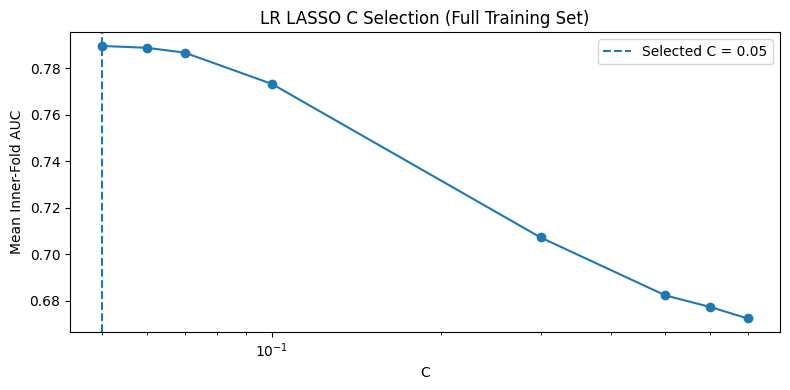

In [24]:
plt.figure(figsize=(8, 4))
plt.semilogx(lr_c_table["C"], lr_c_table["mean_auc"], marker="o")
plt.axvline(full_lr_c, linestyle="--", label=f"Selected C = {full_lr_c}")

plt.title("LR LASSO C Selection (Full Training Set)")
plt.xlabel("C")
plt.ylabel("Mean Inner-Fold AUC")
plt.legend()
plt.tight_layout()

plt.savefig(OUT_DIR / "NB3_LASSO_regularization_path.png", dpi=140)
plt.show()

### **RF/ANN Bootstrapped Permutation Importance**

In [25]:
def permutation_stability(X, y, algorithm, seed, progress_label=None):
    """
    Perform bootstrapped permutation importance for RF or ANN.

    Returns:
        features: Selected feature names
        table: Feature importance and selection stability summary
    """
    if algorithm not in {"RF", "ANN"}:
        raise ValueError("algorithm must be 'RF' or 'ANN'")

    if not X.index.equals(y.index):
        raise ValueError("X and y indices are not aligned.")

    # Configure algorithm-specific parameters
    config = {
        "RF": {"n_boot": N_BOOTSTRAPS_RF, "n_repeat": N_REPEATS_RF},
        "ANN": {"n_boot": N_BOOTSTRAPS_ANN, "n_repeat": N_REPEATS_ANN}
    }

    n_boot = config[algorithm]["n_boot"]
    n_repeat = config[algorithm]["n_repeat"]

    # Internal training and permutation evaluation split
    X_train, X_perm, y_train_inner, y_perm = train_test_split(X, y, test_size=0.20, stratify=y, random_state=seed)

    importance_results = []
    label = progress_label or algorithm

    # Bootstrap model fitting and permutation importance
    for b in tqdm(range(n_boot), desc=f"{label} | Bootstraps", unit="bootstrap"):
        bootstrap_seed = seed + b
        if algorithm == "RF":
            X_boot, y_boot = resample(
                X_train, y_train_inner,
                replace=True,
                n_samples=len(X_train),
                random_state=bootstrap_seed
            )
            
            model = RandomForestClassifier(
                n_estimators=200,
                max_depth=8,
                class_weight="balanced",
                random_state=bootstrap_seed,
                n_jobs=-1
            )

            model.fit(X_boot, y_boot)
            X_eval = X_perm

        else:  # ANN
            X_boot, y_boot = balanced_bootstrap(X_train, y_train_inner, bootstrap_seed)
            scaler = StandardScaler()
            X_boot_scaled = scaler.fit_transform(X_boot)

            model = MLPClassifier(
                hidden_layer_sizes=(32, 16),
                activation="relu",
                solver="adam",
                alpha=0.01,
                max_iter=ANN_MAX_ITER,
                random_state=bootstrap_seed
            )

            with warnings.catch_warnings():
                warnings.simplefilter("ignore", ConvergenceWarning)
                model.fit(X_boot_scaled, y_boot)

            X_eval = scaler.transform(X_perm)

        # Calculate permutation importance
        result = permutation_importance(
            model,
            X_eval,
            y_perm,
            n_repeats=n_repeat,
            scoring="roc_auc",
            random_state=bootstrap_seed,
            n_jobs=1
        )

        importance_results.append(result.importances_mean)

    # Aggregate importance across bootstrap iterations
    importance_array = np.asarray(importance_results)

    table = pd.DataFrame({
        "feature": X.columns,
        "importance_mean": importance_array.mean(axis=0),
        "importance_std": importance_array.std(axis=0),
        "selection_frequency": (importance_array > 0).mean(axis=0)
    })

    table = table.sort_values(["importance_mean", "feature"], ascending=[False, True]).reset_index(drop=True)

    # Apply feature-selection criteria
    table["selected"] = ((table["selection_frequency"] >= PI_THR) &(table["importance_mean"] > 0))

    features = table.loc[table["selected"], "feature"].tolist()

    if not features:
        raise RuntimeError(f"No {algorithm} features selected. ""Consider reviewing the selection threshold.")

    return features, table

### **Model 2: Random Forest — Bootstrapped Permutation Importance**

Each selection run internally splits its own training rows into a bootstrap pool and permutation-validation rows, trains 200-tree, depth-8 balanced forests, and measures the decrease in validation AUC after shuffling a predictor 10 times. Categories with a >=60% positive-importance frequency and a positive mean are retained. The selection is repeated independently in each outer CV training fold.

**Final Training-Set Selection**

In [26]:
print("=== RANDOM FOREST | FINAL TRAINING-SET SELECTION ===")

full_rf_features, rf_table = permutation_stability(
    X_rfann,
    y_train,
    algorithm="RF",
    seed=RANDOM_STATE,
    progress_label="RF full training"
)

print(f"\nSelected features: {len(full_rf_features)}")
print(rf_table.head(15).to_string(index=False))

# Export selected training and test datasets
rf_train[full_rf_features + ["depressed_flag"]].to_csv(OUT_DIR / "NB3_RandomForest_train.csv", index_label="orig_index")
rf_test[full_rf_features + ["depressed_flag"]].to_csv(OUT_DIR / "NB3_RandomForest_test.csv", index_label="orig_index")

# Export feature-selection summary
rf_table.to_csv(OUT_DIR / "NB3_RandomForest_selection_summary.csv", index=False)

=== RANDOM FOREST | FINAL TRAINING-SET SELECTION ===


RF full training | Bootstraps: 100%|█████████████████████████████████████████████████████████| 30/30 [54:04<00:00, 108.16s/bootstrap]


Selected features: 58
      feature  importance_mean  importance_std  selection_frequency  selected
          C1J         0.020968        0.015216             0.966667      True
          C1I         0.019218        0.009423             1.000000      True
     se_score         0.016211        0.010560             1.000000      True
          C1G         0.009132        0.007954             0.966667      True
          G95         0.008324        0.006559             0.933333      True
         B31F         0.006083        0.005635             0.900000      True
          D8G         0.005451        0.003772             0.933333      True
          G94         0.004692        0.006357             0.833333      True
          D51         0.004282        0.004089             0.900000      True
           C3         0.003625        0.004715             0.766667      True
age_first_sex         0.003523        0.002695             0.933333      True
          D8H         0.003465        0.0

**Outer Fold-Specific Selection**

In [ ]:
print("\n=== RANDOM FOREST | FOLD-SPECIFIC SELECTION ===")

for fold in fold_records:
    fold_no = fold["fold"]
    train_idx = fold["train_idx"]

    print(f"\nStarting RF fold {fold_no}/{N_FOLDS}")

    # Retrieve the current outer training fold
    X_fold = (fold_prepared[fold_no]["RF"].loc[train_idx].drop(columns=["depressed_flag"]))
    y_fold = y_train.loc[train_idx]

    # Perform feature selection using outer training data only
    fold_features, fold_table = permutation_stability(
        X_fold,
        y_fold,
        algorithm="RF",
        seed=fold["seed"],
        progress_label=f"RF fold {fold_no}/{N_FOLDS}"
    )

    # Save fold-specific datasets and feature selections
    save_fold("RF", fold, fold_features)

    fold_table.to_csv(FOLDS_DIR / f"fold_{fold_no}_RF_selection_summary.csv", index=False)
    print(f"Completed RF fold {fold_no}/{N_FOLDS}: "f"{len(fold_features)} features selected")

print("\nRandom Forest feature selection completed.")


=== RANDOM FOREST | FOLD-SPECIFIC SELECTION ===

Starting RF fold 1/5


RF fold 1/5 | Bootstraps: 100%|████████████████████████████████████████████████████████████| 30/30 [1:34:10<00:00, 188.34s/bootstrap]


Completed RF fold 1/5: 68 features selected

Starting RF fold 2/5


RF fold 2/5 | Bootstraps: 100%|████████████████████████████████████████████████████████████| 30/30 [7:34:24<00:00, 908.82s/bootstrap]


Completed RF fold 2/5: 33 features selected

Starting RF fold 3/5


RF fold 3/5 | Bootstraps:  87%|████████████████████████████████████████████████████        | 26/30 [1:26:56<14:24, 216.18s/bootstrap]

### **Model 3: Artificial Neural Network — bootstrapped permutation importance**

Oversample bootstrap training cases, fit `StandardScaler` to those cases only, train MLP `(32,16)` with `alpha=0.01`, and measure AUC permutation importance on the internal validation pool. Repeat 30 bootstraps, 10 permutation repeats, and retain >=60% positive with positive mean importance. Repeat independently for each outer training fold.

**Final Training-Set Selection**

In [ ]:
print("=== ANN | FINAL TRAINING-SET SELECTION ===")

full_ann_features, ann_table = permutation_stability(
    X_rfann,
    y_train,
    algorithm="ANN",
    seed=RANDOM_STATE,
    progress_label="ANN full training"
)

print(f"\nSelected features: {len(full_ann_features)}")
print(ann_table.head(15).to_string(index=False))

# Export selected training and test datasets
rf_train[full_ann_features + ["depressed_flag"]].to_csv(OUT_DIR / "NB3_ANN_train.csv", index_label="orig_index")
rf_test[full_ann_features + ["depressed_flag"]].to_csv(OUT_DIR / "NB3_ANN_test.csv", index_label="orig_index")

# Export feature-selection summary
ann_table.to_csv(OUT_DIR / "NB3_ANN_selection_summary.csv", index=False)

**Outer Fold-Specific Selection**

In [ ]:
print("\n=== ANN | FOLD-SPECIFIC SELECTION ===")

for fold in fold_records:
    fold_no = fold["fold"]
    train_idx = fold["train_idx"]

    print(f"\nStarting ANN fold {fold_no}/{N_FOLDS}")

    # Retrieve the current outer training fold
    X_fold = (fold_prepared[fold_no]["ANN"].loc[train_idx].drop(columns=["depressed_flag"]))
    y_fold = y_train.loc[train_idx]

    # Perform feature selection using outer training data only
    fold_features, fold_table = permutation_stability(
        X_fold,
        y_fold,
        algorithm="ANN",
        seed=fold["seed"],
        progress_label=f"ANN fold {fold_no}/{N_FOLDS}"
    )

    # Save fold-specific datasets and feature selections
    save_fold("ANN", fold, fold_features)

    fold_table.to_csv(FOLDS_DIR / f"fold_{fold_no}_ANN_selection_summary.csv", index=False)

    print(f"Completed ANN fold {fold_no}/{N_FOLDS}: "f"{len(fold_features)} features selected")

print("\nANN feature selection completed.")

### **Feature-selection comparison and fold manifest for NB4**

**RF and ANN Feature-Selection Comparison**

In [ ]:
rf_ann_summary = pd.DataFrame({"feature": X_rfann.columns})

# Combine RF and ANN importance and selection results
for model, table in [("RF", rf_table), ("ANN", ann_table)]:
    model_summary = table.rename(columns={
        "importance_mean": f"{model}_importance_mean",
        "importance_std": f"{model}_importance_std",
        "selection_frequency": f"{model}_selection_frequency",
        "selected": f"{model}_selected"
    })

    columns = ["feature", f"{model}_importance_mean", f"{model}_importance_std", f"{model}_selection_frequency", f"{model}_selected"]
    rf_ann_summary = rf_ann_summary.merge(model_summary[columns], on="feature", how="left", validate="one_to_one")

# Count how many models selected each feature
rf_ann_summary["n_models_selected"] = (rf_ann_summary[["RF_selected", "ANN_selected"]].sum(axis=1))

# Verify that all features have corresponding results
assert rf_ann_summary[["RF_selected", "ANN_selected"]].notna().all().all(), "Missing RF or ANN feature-selection results."

# Export comparison summary
rf_ann_summary.to_csv(OUT_DIR / "NB3_RFANN_feature_selection_summary.csv", index=False)

**Validate Fold-Specific Feature Selection**

In [ ]:
expected_models = {"lr", "rf", "ann"}

assert all(
    set(fold["features"].keys()) == expected_models
    for fold in fold_records
), "One or more folds are missing model feature selections."

assert all(
    set(fold["files"].keys()) == expected_models
    for fold in fold_records
), "One or more folds are missing exported dataset references."

**Generate NB4 Fold Manifest**

In [ ]:
manifest = {"seed": RANDOM_STATE, "n_folds": N_FOLDS,
    "full_selected_features": {
        "lr": full_lr_features,
        "rf": full_rf_features,
        "ann": full_ann_features
    },

    "folds": [{
            "fold": fold["fold"],
            "n_train": fold["n_train"],
            "n_val": fold["n_val"],
            "hds_train": fold["hds_train"],
            "hds_val": fold["hds_val"],
            "best_c": fold["best_c"],
            "features": fold["features"],
            "files": fold["files"]
        }
        for fold in fold_records]
}

# Export manifest for NB4
with open(OUT_DIR / "NB3_foldsafe_manifest.json", "w") as fp:
    json.dump(manifest, fp, indent=2)

**Summarize Fold-Specific Selection Counts**

In [ ]:
counts = pd.DataFrame([
    {
        "fold": fold["fold"],
        "LR_C": fold["best_c"],
        "LR_features": len(fold["features"]["lr"]),
        "RF_features": len(fold["features"]["rf"]),
        "ANN_features": len(fold["features"]["ann"])
    }
    for fold in fold_records
])

# Export fold-specific selection counts
counts.to_csv(OUT_DIR / "NB3_foldsafe_selection_counts.csv", index=False)

**Final Selection Summary**

In [ ]:
print("\n=== FINAL TRAINING-SET FEATURE SELECTION ===")

full_counts = {"LR": len(full_lr_features), "RF": len(full_rf_features), "ANN": len(full_ann_features)}

for model, count in full_counts.items():
    print(f"{model}: {count} selected features")

print("\n=== FOLD-SPECIFIC FEATURE SELECTION ===")
print(counts.to_string(index=False))

print("\n=== NB3 OUTPUT VALIDATION ===")

assert len(fold_records) == N_FOLDS
assert all(set(fold["features"].keys()) == expected_models for fold in fold_records)

print(f"Validated {len(fold_records)} outer folds.")
print(f"Saved {len(fold_records) * 3} fold-specific dataset pairs.")
print("Saved RF-ANN feature-selection comparison.")
print("Saved NB4 fold manifest.")
print("Saved fold-specific selection counts.")

print("\nNB3 FEATURE SELECTION COMPLETED.")
print("Output directory:", OUT_DIR)